In [13]:
#Import Library & Load Dataset Bersih
from pathlib import Path
from datetime import datetime
import duckdb
import polars as pl
import plotly.express as px

DATA_BERSIH_PATH = Path("../data/processed/dataset_bersih.parquet")

if not DATA_BERSIH_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan di {DATA_BERSIH_PATH}. "
        "Pastikan Milestone 2 sudah disimpan."
    )

df = pl.read_parquet(DATA_BERSIH_PATH)
print(f"Dataset bersih dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df.head(3)

Dataset bersih dimuat: 1,028,149 baris x 5 kolom


text,label_text,source,split,text_length
str,str,str,str,u32
"""warung ini dimiliki oleh pengu…","""positive""","""indonlp/indonlu/smsa""","""train""",404
"""mohon ulama lurus dan k212 mmb…","""neutral""","""indonlp/indonlu/smsa""","""train""",102
"""lokasi strategis di jalan suma…","""positive""","""indonlp/indonlu/smsa""","""train""",184


In [14]:
#Pemrosesan Temporal & Ekstraksi Fitur Kalender (Polars)
start_time = datetime(2026, 1, 1, 0, 0, 0)

df_ts = (
    df.with_row_index("doc_id")
    .with_columns([
        (pl.lit(start_time) + pl.duration(seconds=pl.col("doc_id"))).alias("timestamp"),
        pl.col("text").str.split(" ").list.len().alias("word_count"),
    ])
    .sort("timestamp")
    .with_columns([
        # Ekstraksi fitur kalender
        pl.col("timestamp").dt.hour().alias("jam"),
        pl.col("timestamp").dt.weekday().alias("hari_ke"),
        # Lag difference & rolling window pada fitur panjang teks
        (pl.col("text_length") - pl.col("text_length").shift(1)).alias("lag_diff_length"),
        pl.col("text_length").rolling_mean(window_size=500).alias("rolling_mean_500"),
    ])
)

print(f"Total baris diproses: {len(df_ts):,}")
df_ts.select(["timestamp", "label_text", "text_length", "jam", "hari_ke", "lag_diff_length", "rolling_mean_500"]).head(5)

Total baris diproses: 1,028,149


timestamp,label_text,text_length,jam,hari_ke,lag_diff_length,rolling_mean_500
datetime[μs],str,u32,i8,i8,u32,f64
2026-01-01 00:00:00,"""positive""",404,0,4,null,null
2026-01-01 00:00:01,"""neutral""",102,0,4,4294966994,null
2026-01-01 00:00:02,"""positive""",184,0,4,82,null
2026-01-01 00:00:03,"""positive""",93,0,4,4294967205,null
2026-01-01 00:00:04,"""negative""",214,0,4,121,null


In [15]:
#Agregasi Runtun Waktu
df_hourly = (
    df_ts.group_by_dynamic("timestamp", every="1h", group_by="label_text")
    .agg([
        pl.len().alias("jumlah_dokumen"),
        pl.col("text_length").mean().alias("rata_panjang_karakter"),
        pl.col("word_count").mean().alias("rata_jumlah_kata"),
        pl.col("rolling_mean_500").mean().alias("rata_rolling_mean"),
    ])
)

con = duckdb.connect()
con.register("df_clean", df_ts)

print(f"Hasil agregasi per jam: {len(df_hourly):,} baris")
df_hourly.head(5)

Hasil agregasi per jam: 853 baris


label_text,timestamp,jumlah_dokumen,rata_panjang_karakter,rata_jumlah_kata,rata_rolling_mean
str,datetime[μs],u32,f64,f64,f64
"""neutral""",2026-01-01 00:00:00,355,86.292958,14.315493,193.262187
"""neutral""",2026-01-01 01:00:00,397,94.125945,15.574307,187.265441
"""neutral""",2026-01-01 02:00:00,379,85.841689,14.248021,188.849346
"""neutral""",2026-01-01 03:00:00,529,237.342155,39.589792,256.656272
"""neutral""",2026-01-01 04:00:00,675,328.792593,55.306667,341.799265


In [16]:
#Grafik Interaktif 1 — Tren Temporal
df_hourly = (
    df_ts.group_by_dynamic("timestamp", every="1h", group_by="label_text")
    .agg([
        pl.len().alias("jumlah_dokumen"),
        pl.col("text_length").mean().alias("rata_panjang_karakter"),
        pl.col("word_count").mean().alias("rata_jumlah_kata"),
        pl.col("rolling_mean_500").mean().alias("rata_rolling_mean"),
    ])
)

con = duckdb.connect()
con.register("df_clean", df_ts)

print(f"Hasil agregasi per jam: {len(df_hourly):,} baris")
df_hourly.head(5)

Hasil agregasi per jam: 853 baris


label_text,timestamp,jumlah_dokumen,rata_panjang_karakter,rata_jumlah_kata,rata_rolling_mean
str,datetime[μs],u32,f64,f64,f64
"""neutral""",2026-01-01 00:00:00,355,86.292958,14.315493,193.262187
"""neutral""",2026-01-01 01:00:00,397,94.125945,15.574307,187.265441
"""neutral""",2026-01-01 02:00:00,379,85.841689,14.248021,188.849346
"""neutral""",2026-01-01 03:00:00,529,237.342155,39.589792,256.656272
"""neutral""",2026-01-01 04:00:00,675,328.792593,55.306667,341.799265


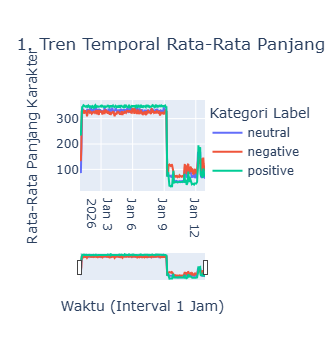

In [17]:
#Grafik Interaktif 2 — Distribusi Kelas Label
fig1 = px.line(
    df_hourly,
    x="timestamp",
    y="rata_panjang_karakter",
    color="label_text",
    hover_data=["jumlah_dokumen", "rata_jumlah_kata", "rata_rolling_mean"],
    title="1. Tren Temporal Rata-Rata Panjang Karakter per Jam (group_by_dynamic)",
    labels={
        "timestamp": "Waktu (Interval 1 Jam)",
        "rata_panjang_karakter": "Rata-Rata Panjang Karakter",
        "label_text": "Kategori Label",
    },
)
fig1.update_xaxes(rangeslider_visible=True)
fig1.show()

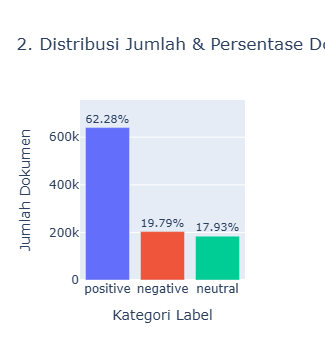

In [18]:
#Grafik Interaktif 3 — Analisis Domain Sumber Data
df_label = pl.from_pandas(con.execute("""
    SELECT 
        label_text,
        COUNT(*) AS jumlah_dokumen,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS persentase,
        ROUND(AVG(text_length), 1) AS rata_panjang_karakter
    FROM df_clean
    GROUP BY label_text
    ORDER BY jumlah_dokumen DESC
""").fetchdf())

fig2 = px.bar(
    df_label,
    x="label_text",
    y="jumlah_dokumen",
    color="label_text",
    text="persentase",
    hover_data=["persentase", "rata_panjang_karakter"],
    title="2. Distribusi Jumlah & Persentase Dokumen per Kategori Label",
    labels={"label_text": "Kategori Label", "jumlah_dokumen": "Jumlah Dokumen"},
)
fig2.update_traces(texttemplate="%{text}%", textposition="outside")
fig2.update_layout(showlegend=False)
fig2.show()

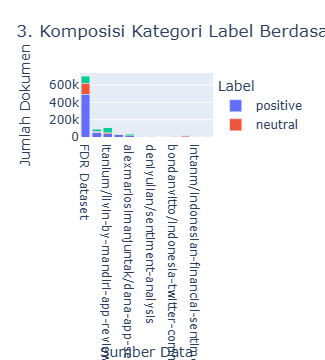

In [19]:
#Grafik Interaktif 4 — Sebaran Panjang Teks per Label
df_source = con.execute("""
    SELECT 
        source,
        label_text,
        COUNT(*) AS total_dokumen,
        ROUND(AVG(word_count), 1) AS rata_kata
    FROM df_clean
    GROUP BY source, label_text
    ORDER BY total_dokumen DESC
""").fetchdf()

fig3 = px.bar(
    df_source,
    x="source",
    y="total_dokumen",
    color="label_text",
    barmode="stack",
    hover_data=["rata_kata"],
    title="3. Komposisi Kategori Label Berdasarkan Sumber Data (Source)",
    labels={"source": "Sumber Data", "total_dokumen": "Jumlah Dokumen", "label_text": "Label"},
)
fig3.show()

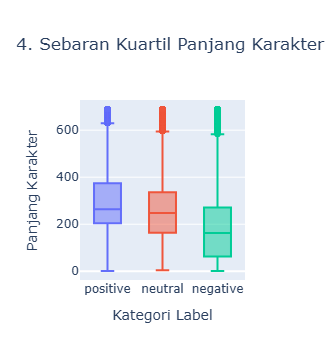

In [20]:
#Grafik Interaktif 5 — Hirarki Partisi Dataset
df_sample = df_ts.sample(n=min(50_000, len(df_ts)), seed=42).to_pandas()

fig4 = px.box(
    df_sample,
    x="label_text",
    y="text_length",
    color="label_text",
    hover_data=["source", "word_count"],
    title="4. Sebaran Kuartil Panjang Karakter (text_length) per Kategori Label",
    labels={"label_text": "Kategori Label", "text_length": "Panjang Karakter"},
)
fig4.update_layout(showlegend=False)
fig4.show()

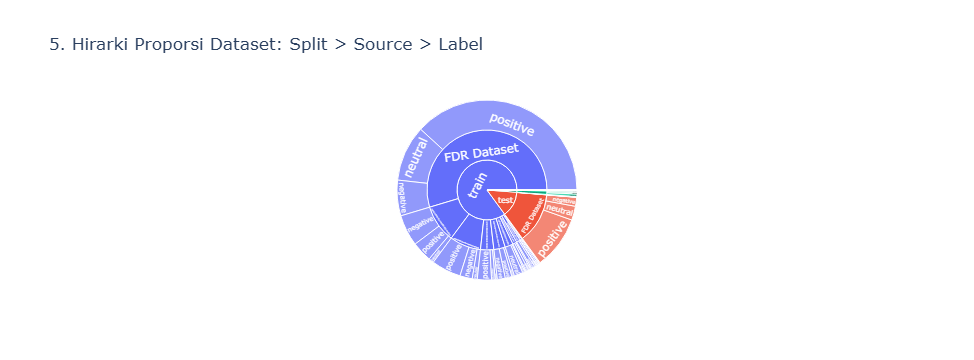

In [22]:
#Grafik Interaktif 6 — Aktivitas Berdasarkan Fitur Kalender
df_sunburst = con.execute("""
    SELECT split, source, label_text, COUNT(*) AS jumlah
    FROM df_clean
    GROUP BY split, source, label_text
""").fetchdf()

fig5 = px.sunburst(
    df_sunburst,
    path=["split", "source", "label_text"],
    values="jumlah",
    title="5. Hirarki Proporsi Dataset: Split > Source > Label",
)
fig5.show()

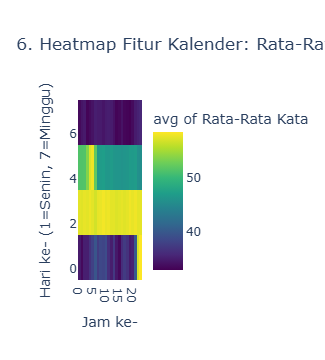

In [23]:
#Grafik Interaktif 6 — Aktivitas Berdasarkan Fitur Kalender
df_cal = con.execute("""
    SELECT 
        hari_ke,
        jam,
        COUNT(*) AS jumlah_dokumen,
        ROUND(AVG(word_count), 1) AS rata_kata
    FROM df_clean
    GROUP BY hari_ke, jam
    ORDER BY hari_ke, jam
""").fetchdf()

fig6 = px.density_heatmap(
    df_cal,
    x="jam",
    y="hari_ke",
    z="rata_kata",
    histfunc="avg",
    nbinsx=24,
    color_continuous_scale="Viridis",
    title="6. Heatmap Fitur Kalender: Rata-Rata Jumlah Kata per Hari dan Jam",
    labels={"jam": "Jam ke-", "hari_ke": "Hari ke- (1=Senin, 7=Minggu)", "rata_kata": "Rata-Rata Kata"},
)
fig6.show()